In [1]:
ROLL_NO = 1024160078
NAME = "Krish BHasin"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

In [2]:
pip install matplotlib

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:

df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160078   Name: Krish BHasin   Fingerprint: CE9FFC28   Tickets: 15

Ticket_ID                                                                                    Ticket_Text
      T01                                    The password stopped responding. Is there another solution?
      T02                   Projector failed to open before the assignment deadline. Can you check this?
      T03                                                   Call me on +91 98765 43210 or 0175-239-3201.
      T04 I couldn't connect to the Python before the assignment deadline. It works on another computer.
      T05                                     Matlab keeps asking for login during the lab. Please help.
      T06                                                           Python 3.12 was installed yesterday.
      T07              Python is running slowly after resetting my password. I have tried several times!
      T08                                  Lms is showing an error after the

In [6]:
rows = []
all_tokens_corpus = []
all_final_corpus = []

for _, row in df.iterrows():
    res = process_ticket(row["Ticket_Text"])
    all_tokens_corpus.extend(res["tokens"])
    all_final_corpus.extend(res["final"])
    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Tokens": len(set(res["tokens"])),
        "Final_Tokens": len(res["final"])
    })

q1_df = pd.DataFrame(rows)

total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation": q1_df["Punctuation"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique_Tokens": len(set(all_tokens_corpus)),
    "Final_Tokens": q1_df["Final_Tokens"].sum()
}])

q1_table = pd.concat([q1_df, total_row], ignore_index=True)
print(q1_table.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      10            2          3             10             5
      T02          2      14            2          6             14             6
      T03          1       9            1          3              9             5
      T04          2      18            2          7             16             9
      T05          2      12            2          3             11             7
      T06          1       6            1          1              6             4
      T07          2      15            2          5             15             8
      T08          2      13            2          4             12             7
      T09          2      11            2          4              9             5
      T10          2      10            4          2              9             4
      T11          1       7            1          2              7             4
      T12       

In [7]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

EMAIL_PAT = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'
URL_PAT   = r'(?:https?://|www\.)[^\s;,]+'
PHONE_PAT = r'(?:\+91[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})'
NUMBER_PAT = r'\b(?:0x[0-9a-fA-F]+|\d+(?:[.,]\d+)*)\b'

print("VERIFYING RE.SUB ON TEST_LINES:")
for i, line in enumerate(TEST_LINES, 1):
    subbed = re.sub(EMAIL_PAT, "<EMAIL>", line)
    subbed = re.sub(URL_PAT, "<URL>", subbed)
    subbed = re.sub(PHONE_PAT, "<PHONE>", subbed)
    print(f"Test Line {i}:\n  {subbed}\n")

raw_corpus = " ".join(df["Ticket_Text"].tolist())

words_gt_5 = sorted(list(set(re.findall(r'\b[a-zA-Z]{6,}\b', raw_corpus))))

numbers_extracted = sorted(list(set(re.findall(NUMBER_PAT, raw_corpus))))

capitalized_words = sorted(list(set(re.findall(r'\b[A-Z][a-zA-Z]*\b', raw_corpus))))

vowel_words = sorted(list(set(re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', raw_corpus))))

print("EXTRACTIONS ON RAW TICKETS:")
print(f"1. Words > 5 letters ({len(words_gt_5)} unique): {words_gt_5[:12]} ...")
print(f"2. Numbers extracted ({len(numbers_extracted)} unique): {numbers_extracted}")
print(f"3. Capitalized words ({len(capitalized_words)} unique): {capitalized_words}")
print(f"4. Words starting with a vowel ({len(vowel_words)} unique): {vowel_words[:12]} ...\n")

df["Masked_Ticket"] = df["Ticket_Text"].apply(
    lambda text: re.sub(PHONE_PAT, "<PHONE>", re.sub(URL_PAT, "<URL>", re.sub(EMAIL_PAT, "<EMAIL>", text)))
)

masked_subset = df[df["Masked_Ticket"] != df["Ticket_Text"]][["Ticket_ID", "Ticket_Text", "Masked_Ticket"]]
print("TICKETS MODIFIED BY RE.SUB:")
print(masked_subset.to_string(index=False) if len(masked_subset) > 0 else "No masked entities present in these tickets.")

VERIFYING RE.SUB ON TEST_LINES:
Test Line 1:
  Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Test Line 2:
  Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Test Line 3:
  The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

EXTRACTIONS ON RAW TICKETS:
1. Words > 5 letters (43 unique): ['Matlab', 'Nothing', 'Password', 'Please', 'Projector', 'Python', 'Server', 'another', 'asking', 'assignment', 'before', 'campus'] ...
2. Numbers extracted (7 unique): ['0175', '239', '3.12', '3201', '43210', '91', '98765']
3. Capitalized words (19 unique): ['ASAP', 'Call', 'Can', 'Fi', 'I', 'Is', 'It', 'Lms', 'Matlab', 'Nothing', 'Password', 'Please', 'Pls', 'Projector', 'Python', 'Server', 'The', 'This', 'Wi']
4. Words starting with a vowel (21 unique): ['ASAP', 'I', 'Is', 'It', 'after', 'an', 'and', 'another', 'asking', 'assignment', 'error', 'installed'] ...

TICKETS MODIFIED BY RE.SUB:
Ticket_ID                                  Ticket_Text            

In [8]:
from nltk.tokenize import RegexpTokenizer

custom_pattern = r'''(?x)
    (?:https?://|www\.)[^\s;,]+                             # URLs
    | [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}       # Emails
    | (?:\+91[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})   # Phone numbers
    | \b\d+(?:\.\d+)+(?:%|\b)                                # Decimals & version numbers (e.g., 95.5%, 2.0.1)
    | \b\d{1,3}(?:,\d{3})+\b                                 # Comma formatted integers (e.g., 1,250)
    | \b[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+\b                    # Hyphenated words (e.g., Wi-Fi, state-of-the-art)
    | \b[A-Za-z]+'[A-Za-z]+\b                                # Contractions (e.g., isn't, didn't, Rao's)
    | \b[A-Za-z]+\b                                          # Regular words
    | \b\d+\b                                                # Standalone digits
    | [^\s\w]                                                # Punctuation / symbols
'''

custom_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("COMPARISON ON TEST_LINES:")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\n--- Line {i} ---")
    print("my_tokenize   :", my_tokenize(line))
    print("word_tokenize :", word_tokenize(line))

print("\nCOMPARISON ON GENERATED TICKETS:")
diff_tickets = []
for _, row in df.iterrows():
    t_my = my_tokenize(row["Ticket_Text"])
    t_word = word_tokenize(row["Ticket_Text"])
    if t_my != t_word:
        diff_tickets.append((row["Ticket_ID"], row["Ticket_Text"], t_my, t_word))

print(f"Total tickets: {len(df)}")
print(f"Tickets tokenized differently: {len(diff_tickets)} out of {len(df)} ({len(diff_tickets) / len(df) * 100:.1f}%)")

if diff_tickets:
    tid, text, t_my, t_word = diff_tickets[0]
    print(f"\nExample Difference ({tid}):")
    print("Original Text :", text)
    print("my_tokenize   :", t_my)
    print("word_tokenize :", t_word)

COMPARISON ON TEST_LINES:

--- Line 1 ---
my_tokenize   : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--- Line 2 ---
my_tokenize   : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

--- Line 3 ---
my_tokenize   : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize : ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.

In [9]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

unique_final_words = sorted(list(set(all_final_corpus)))

porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(r'(ing|ed|es|s|ly)$', min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    """Map POS tag to first character recognized by wordnet.lemmatize()"""
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

tagged_words = nltk.pos_tag(unique_final_words)

records = []
for word, tag in tagged_words:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)
    wn_pos = get_wordnet_pos(tag)
    w_lemma = lemmatizer.lemmatize(word, pos=wn_pos)


    if not (p_stem == l_stem == r_stem == w_lemma):
        records.append({
            "Word": word,
            "POS_Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": w_lemma
        })

diff_df = pd.DataFrame(records)
print(f"Total Unique Final Tokens: {len(unique_final_words)}")
print(f"Words with Differing Stem/Lemma Outputs: {len(diff_df)}\n")
print(diff_df.to_string(index=False))

Total Unique Final Tokens: 65
Words with Differing Stem/Lemma Outputs: 36

      Word POS_Tag    Porter Lancaster     Regexp Lemmatizer
   another      DT     anoth     anoth    another    another
assignment      NN    assign    assign assignment assignment
      call      VB      call       cal       call       call
    campus      NN     campu      camp      campu     campus
   changed     VBN     chang     chang      chang     change
  computer      NN    comput    comput   computer   computer
  deadline      JJ   deadlin   deadlin   deadline   deadline
     error      NN     error        er      error      error
      file      NN      file       fil       file       file
 installed     VBN    instal    instal    install     instal
    latest     JJS    latest    latest     latest       late
       lms      NN        lm       lms        lms         lm
    nobody      JJ    nobodi    nobody     nobody     nobody
   nothing      NN      noth      noth       noth    nothing
      open

CORPUS STATISTICS(TTR)
               Stage  Total Tokens (N)  Unique Tokens (V)  TTR (V/N)
     S1 (All tokens)               186                 96     0.5161
 S2 (No punctuation)               157                 91     0.5796
   S3 (Final tokens)                96                 65     0.6771
S4 (S3 after Porter)                96                 61     0.6354
Top 10 Words in S1 (All Tokens):
  .               : 21
  the             : 11
  is              : 8
  ?               : 5
  i               : 5
  password        : 4
  n't             : 4
  another         : 3
  to              : 3
  before          : 3

Top 10 Words in S3 (Final Tokens):
  password        : 4
  n't             : 4
  another         : 3
  assignment      : 3
  deadline        : 3
  python          : 3
  running         : 3
  slowly          : 3
  stopped         : 2
  responding      : 2
Top 5 Bigrams in S1:
  ('.', 'i')                     : 5
  ('.', 'is')                    : 3
  ('before', 'the')       

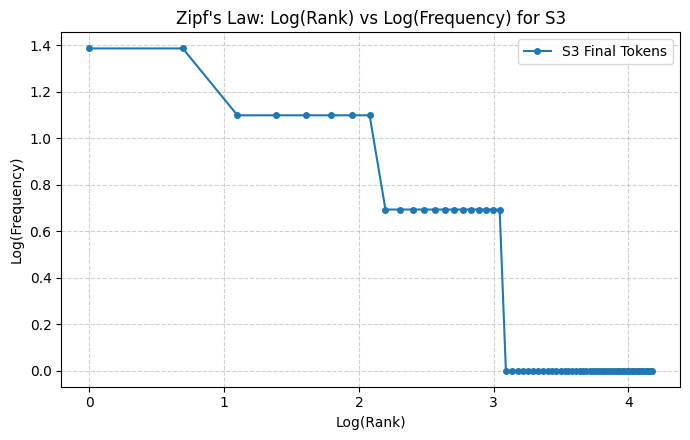

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Define Corpus Stages S1, S2, S3, S4
S1 = all_tokens_corpus
S2 = [t for t in S1 if not is_punct(t)]
S3 = all_final_corpus
S4 = [porter.stem(t) for t in S3]

stages = {
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (S3 after Porter)": S4
}

# 1. Corpus Statistics Table
stats = []
for name, tokens in stages.items():
    n = len(tokens)
    v = len(set(tokens))
    ttr = v / n if n > 0 else 0
    stats.append({
        "Stage": name,
        "Total Tokens (N)": n,
        "Unique Tokens (V)": v,
        "TTR (V/N)": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
print("CORPUS STATISTICS(TTR)")
print(stats_df.to_string(index=False))


# 2. Top 10 Words in S1 and S3
top10_s1 = Counter(S1).most_common(10)
top10_s3 = Counter(S3).most_common(10)

print("Top 10 Words in S1 (All Tokens):")
for w, c in top10_s1:
    print(f"  {w:<15} : {c}")

print("\nTop 10 Words in S3 (Final Tokens):")
for w, c in top10_s3:
    print(f"  {w:<15} : {c}")


# 3. Top 5 Bigrams in S1 and S3
bigrams_s1 = list(nltk.bigrams(S1))
bigrams_s3 = list(nltk.bigrams(S3))

print("Top 5 Bigrams in S1:")
for bg, c in Counter(bigrams_s1).most_common(5):
    print(f"  {str(bg):<30} : {c}")

print("\nTop 5 Bigrams in S3:")
for bg, c in Counter(bigrams_s3).most_common(5):
    print(f"  {str(bg):<30} : {c}")

# 4. Plot Log(Rank) vs Log(Frequency) for S3 (Zipf's Law)
freqs_s3 = sorted(Counter(S3).values(), reverse=True)
ranks_s3 = list(range(1, len(freqs_s3) + 1))

log_ranks = np.log(ranks_s3)
log_freqs = np.log(freqs_s3)

plt.figure(figsize=(7, 4.5))
plt.plot(log_ranks, log_freqs, marker='o', markersize=4, linestyle='-', color='#1f77b4', label='S3 Final Tokens')
plt.title("Zipf's Law: Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()